<a href="https://colab.research.google.com/github/MagFilho/Projeto-Dengue-Alerta/blob/main/DengueAlertaFinal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dengue Alerta: Previsão de Pressão Epidemiológica

Este notebook implementa a análise de séries temporais e detecção de anomalias para estimar localidades e períodos com maior risco de aumento de casos de dengue, auxiliando equipes de saúde na tomada de decisão rápida.

### Datasets Originais:
* **Casos de Dengue (Arboviroses):** [Dados Abertos - Saúde](https://dadosabertos.saude.gov.br/dataset/arboviroses-dengue)
* **Dados Climáticos:** [INMET (BDMEP)](https://bdmep.inmet.gov.br)

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import os

sns.set_theme(style="whitegrid")
print("Bibliotecas básicas importadas com sucesso.")

Bibliotecas básicas importadas com sucesso.


## 1. Coleta e Preparação do Ambiente

### 1.1 Coleta de Dados de Clima Secundários (Open-Meteo API)

Utilização da API do Open-Meteo para obter dados climáticos retroativos de referência nacional.

In [13]:
# Instalação de bibliotecas auxiliares para ler arquivos DBF do DATASUS (caso baixe direto do FTP)
!pip install dbfread openmeteo-requests requests-cache retry -q

import openmeteo_requests
import requests_cache
import pandas as pd
from retry import retry

# Configurando cache para a API do Open-Meteo para evitar requisições repetidas lentas
cache_session = requests_cache.CachedSession('.cache', expire_after = -1)
openmeteo = openmeteo_requests.Client(session = cache_session)

def obter_clima_real(latitude, longitude, data_inicio, data_fim):
    """
    Busca temperatura média e precipitação diária reais para uma coordenada geográfica.
    Exemplo padrão: Latitude/Longitude de uma cidade brasileira.
    """
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": data_inicio,
        "end_date": data_fim,
        "daily": ["temperature_2m_mean", "rain_sum"],
        "timezone": "America/Sao_Paulo"
    }

    responses = openmeteo.weather_api(url, params=params)
    response = responses[0]

    # Processando dados diários
    daily = response.Daily()
    daily_temperature_2m_mean = daily.Variables(0).ValuesAsNumpy()
    daily_rain_sum = daily.Variables(1).ValuesAsNumpy()

    datas_clima = pd.date_range(
        start = pd.to_datetime(daily.Time(), unit = "s", utc = True),
        end = pd.to_datetime(daily.TimeEnd(), unit = "s", utc = True),
        freq = pd.Timedelta(seconds = daily.Interval()),
        inclusive = "left"
    )

    df_clima = pd.DataFrame(data = {
        "data": datas_clima.tz_convert("America/Sao_Paulo").tz_localize(None), # Remover fuso para merge limpo
        "temperatura_media": daily_temperature_2m_mean,
        "precipitacao_mm": daily_rain_sum
    })

    return df_clima

# Exemplo prático: Buscando clima real de Belo Horizonte - MG (2021 a 2023)
print("Buscando dados climáticos históricos reais do Open-Meteo...")
df_clima_real = obter_clima_real(latitude=-19.91, longitude=-43.93, data_inicio="2021-01-01", data_fim="2023-12-31")
display(df_clima_real.head())
print(f"Dados climáticos reais obtidos com sucesso! Total de dias: {len(df_clima_real)}")

Buscando dados climáticos históricos reais do Open-Meteo...


,data,temperatura_media,precipitacao_mm
0,2021-01-01,23.185417,8.200000
1,2021-01-02,21.141666,11.200001
2,2021-01-03,20.539583,27.700001
3,2021-01-04,21.000002,14.900002
4,2021-01-05,22.325003,0.600000


Dados climáticos reais obtidos com sucesso! Total de dias: 1095


## 2. Ingestão de Dados Oficiais de Arboviroses (Dengue 2025)

Leitura e filtragem dos registros oficiais de notificações de dengue obtidos no Portal de Dados Abertos da Saúde.

In [11]:
import pandas as pd
import urllib.request
import ssl
import os

ssl._create_default_https_context = ssl._create_unverified_context

# URL direta do arquivo de dados abertos para o ano de 2025
url_dengue_2025 = "https://dadosabertos.saude.gov.br/dataset/3349603e-ed3a-449e-b8d4-83952f4b5030/resource/b95b86aa-3efd-4e2b-bb66-cf29b43475f4/download/arboviroses_dengue_2025.csv"
csv_local = "arboviroses_dengue_2025.csv"

# Se você já baixou o arquivo manualmente e arrastou para o Colab, ele pulará o download
if os.path.exists(csv_local):
    print(f"Arquivo '{csv_local}' já detectado localmente. Carregando dados...")
    df_dengue_2025 = pd.read_csv(csv_local, sep=";", encoding="utf-8", nrows=5000, low_memory=False)
    display(df_dengue_2025.head())
else:
    try:
        print("Tentando baixar dados reais de Dengue de 2025 com cabeçalhos simulados...")
        req = urllib.request.Request(
            url_dengue_2025,
            headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
        )
        with urllib.request.urlopen(req) as response, open(csv_local, 'wb') as out_file:
            out_file.write(response.read())
        print("Download completo!")
        df_dengue_2025 = pd.read_csv(csv_local, sep=";", encoding="utf-8", nrows=5000, low_memory=False)
        display(df_dengue_2025.head())
    except Exception as e:
        print(f"Não foi possível baixar automaticamente devido ao bloqueio do servidor: {e}")
        print("DICA: Acesse https://dadosabertos.saude.gov.br/dataset/arboviroses-dengue, faça o download do CSV de 2025 manualmente, mude o nome do arquivo baixado para 'arboviroses_dengue_2025.csv' e faça o upload dele na barra lateral esquerda do Colab (ícone de pasta).")

Arquivo 'arboviroses_dengue_2025.csv' já detectado localmente. Carregando dados...


,"TP_NOT,ID_AGRAVO,DT_NOTIFIC,SEM_NOT,NU_ANO,SG_UF_NOT,ID_MUNICIP,ID_REGIONA,ID_UNIDADE,DT_SIN_PRI,SEM_PRI,ANO_NASC,NU_IDADE_N,CS_SEXO,CS_GESTANT,CS_RACA,CS_ESCOL_N,SG_UF,ID_MN_RESI,ID_RG_RESI,ID_PAIS,DT_INVEST,ID_OCUPA_N,FEBRE,MIALGIA,CEFALEIA,EXANTEMA,VOMITO,NAUSEA,DOR_COSTAS,CONJUNTVIT,ARTRITE,ARTRALGIA,PETEQUIA_N,LEUCOPENIA,LACO,DOR_RETRO,DIABETES,HEMATOLOG,HEPATOPAT,RENAL,HIPERTENSA,ACIDO_PEPT,AUTO_IMUNE,DT_CHIK_S1,DT_CHIK_S2,DT_PRNT,RES_CHIKS1,RES_CHIKS2,RESUL_PRNT,DT_SORO,RESUL_SORO,DT_NS1,RESUL_NS1,DT_VIRAL,RESUL_VI_N,DT_PCR,RESUL_PCR_,SOROTIPO,HISTOPA_N,IMUNOH_N,HOSPITALIZ,DT_INTERNA,UF,MUNICIPIO,TPAUTOCTO,COUFINF,COPAISINF,COMUNINF,CLASSI_FIN,CRITERIO,DOENCA_TRA,CLINC_CHIK,EVOLUCAO,DT_OBITO,DT_ENCERRA,ALRM_HIPOT,ALRM_PLAQ,ALRM_VOM,ALRM_SANG,ALRM_HEMAT,ALRM_ABDOM,ALRM_LETAR,ALRM_HEPAT,ALRM_LIQ,DT_ALRM,GRAV_PULSO,GRAV_CONV,GRAV_ENCH,GRAV_INSUF,GRAV_TAQUI,GRAV_EXTRE,GRAV_HIPOT,GRAV_HEMAT,GRAV_MELEN,GRAV_METRO,GRAV_SANG,GRAV_AST,GRAV_MIOC,GRAV_CONSC,GRAV_ORGAO,DT_GRAV,MANI_HEMOR,EPISTAXE,GENGIVO,METRO,PETEQUIAS,HEMATURA,SANGRAM,LACO_N,PLASMATICO,EVIDENCIA,PLAQ_MENOR,CON_FHD,COMPLICA,TP_SISTEMA,NDUPLIC_N,DT_DIGITA,CS_FLXRET,FLXRECEBI,MIGRADO_W"
0,"2,A90,2024-12-29,202501,2024,32,320070,32004,2..."
1,"2,A90,2024-12-29,202501,2024,32,320020,32004,2..."
2,"2,A90,2024-12-29,202501,2024,32,320020,32004,2..."
3,"2,A90,2024-12-29,202501,2024,32,320020,32004,2..."
4,"2,A90,2024-12-29,202501,2024,32,320020,32004,2..."


## 3. Coleta e Extração de Dados Meteorológicos Oficiais (INMET 2025)

Download do pacote consolidado de dados meteorológicos históricos das estações automáticas do INMET para o ano de 2025.

In [14]:
import zipfile
import urllib.request
import ssl
import os

ssl._create_default_https_context = ssl._create_unverified_context

url_inmet_2025 = "https://portal.inmet.gov.br/uploads/dadoshistoricos/2025.zip"
zip_local = "inmet_2025.zip"
pasta_extracao = "inmet_2025_extraido"

# 1. Fluxo de verificação/download inteligente
if os.path.exists(zip_local):
    print(f"Arquivo local '{zip_local}' detectado com sucesso!")
else:
    try:
        print("Tentando baixar ZIP do INMET de 2025 simulando requisição de navegador...")
        req = urllib.request.Request(
            url_inmet_2025,
            headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
        )
        with urllib.request.urlopen(req) as response, open(zip_local, 'wb') as out_file:
            out_file.write(response.read())
        print("Download do ZIP do INMET concluído com sucesso!")
    except Exception as e:
        print(f"Erro ao obter dados automaticamente do INMET: {e}")
        print("Por favor, certifique-se de que fez o upload manual do arquivo 'inmet_2025.zip' no painel esquerdo do Colab.")

# 2. Descompactação dos arquivos
if os.path.exists(zip_local):
    try:
        print("Descompactando banco de dados climáticos do INMET...")
        with zipfile.ZipFile(zip_local, 'r') as zip_ref:
            zip_ref.extractall(pasta_extracao)
        print("Extração concluída!")

        # Listar estações para verificar se deu certo
        estacoes = []
        for root, dirs, files in os.walk(pasta_extracao):
            for file in files:
                if file.upper().endswith('.CSV'):
                    estacoes.append(os.path.join(root, file))

        print(f"Total de estações encontradas em 2025: {len(estacoes)}")
        if estacoes:
            print("Algumas estações disponíveis para análise:")
            for f in estacoes[:5]:
                print(os.path.basename(f))
    except Exception as e:
        print(f"Falha ao descompactar o arquivo: {e}")
else:
    print("Não foi possível proceder com a extração pois o arquivo ZIP não está disponível.")

Arquivo local 'inmet_2025.zip' detectado com sucesso!
Descompactando banco de dados climáticos do INMET...
Extração concluída!
Total de estações encontradas em 2025: 594
Algumas estações disponíveis para análise:
INMET_SE_SP_A764_BEBEDOURO_01-01-2025_A_31-12-2025.CSV
INMET_N_TO_A051_PIUM_01-01-2025_A_31-12-2025.CSV
INMET_SE_SP_A713_IPERO_01-01-2025_A_31-12-2025.CSV
INMET_NE_BA_A437_UNA_01-01-2025_A_31-12-2025.CSV
INMET_N_PA_A213_TOME ACU_01-01-2025_A_31-12-2025.CSV


### 3.1 Seleção e Filtro de Estações Meteorológicas

Identificação e seleção das planilhas de estações disponíveis para o estudo (Exemplo: Mossoró - RN).

In [15]:
import os
import glob
import pandas as pd

# Como os arquivos foram extraídos diretamente na raiz ou em pasta específica,
# fazemos uma busca robusta por arquivos .CSV climáticos do INMET
caminhos_possiveis = [
    "inmet_2025_extraido",
    ".",  # Raiz do Colab
    "/content"
]

arquivos_csv = []
for caminho in caminhos_possiveis:
    if os.path.exists(caminho):
        arquivos_csv.extend(glob.glob(os.path.join(caminho, "**", "INMET_*.CSV"), recursive=True))
        arquivos_csv.extend(glob.glob(os.path.join(caminho, "**", "INMET_*.csv"), recursive=True))
        # Tenta também sem o prefixo INMET_ caso tenham sido renomeados
        if not arquivos_csv:
            arquivos_csv.extend(glob.glob(os.path.join(caminho, "*.CSV")))

# Remover duplicatas mantendo caminhos absolutos/limpos
arquivos_csv = list(set([os.path.abspath(f) for f in arquivos_csv]))

print(f"Foram encontrados {len(arquivos_csv)} arquivos de estações meteorológicas locais.")

if len(arquivos_csv) > 0:
    print("\nExemplo das primeiras estações encontradas:")
    for i, arq in enumerate(sorted(arquivos_csv)[:10]):
        print(f"{i}: {os.path.basename(arq)}")

    # Selecionamos a estação de Mossoró como padrão se disponível, ou a primeira da lista
    estacao_selecionada = None
    for arq in arquivos_csv:
        if "MOSSORO" in arq.upper():
            estacao_selecionada = arq
            break

    if not estacao_selecionada:
        estacao_selecionada = arquivos_csv[0]

    print(f"\nLendo dados climáticos da estação selecionada: {os.path.basename(estacao_selecionada)}")
    df_inmet_exemplo = pd.read_csv(estacao_selecionada, sep=";", encoding="latin-1", skiprows=8)
    display(df_inmet_exemplo.head())
else:
    print("Nenhuma planilha de estação foi encontrada. Certifique-se de que os arquivos extraídos estão na pasta raiz ou em 'inmet_2025_extraido'.")

Foram encontrados 594 arquivos de estações meteorológicas locais.

Exemplo das primeiras estações encontradas:
0: INMET_CO_DF_A001_BRASILIA_01-01-2025_A_31-12-2025.CSV
1: INMET_CO_DF_A042_BRAZLANDIA_01-01-2025_A_31-12-2025.CSV
2: INMET_CO_DF_A045_AGUAS EMENDADAS_01-01-2025_A_31-12-2025.CSV
3: INMET_CO_DF_A046_GAMA (PONTE ALTA)_01-01-2025_A_31-12-2025.CSV
4: INMET_CO_DF_A047_PARANOA (COOPA-DF)_01-01-2025_A_31-12-2025.CSV
5: INMET_CO_GO_A002_GOIANIA_01-01-2025_A_31-12-2025.CSV
6: INMET_CO_GO_A003_MORRINHOS_01-01-2025_A_31-12-2025.CSV
7: INMET_CO_GO_A005_PORANGATU_01-01-2025_A_31-12-2025.CSV
8: INMET_CO_GO_A011_SAO SIMAO_01-01-2025_A_31-12-2025.CSV
9: INMET_CO_GO_A012_LUZIANIA_01-01-2025_A_31-12-2025.CSV

Lendo dados climáticos da estação selecionada: INMET_NE_RN_A318_MOSSORO_01-01-2025_A_31-12-2025.CSV


,Data,Hora UTC,"PRECIPITAÇÃO TOTAL, HORÁRIO (mm)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)",PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB),PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB),RADIACAO GLOBAL (Kj/m²),"TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)",TEMPERATURA DO PONTO DE ORVALHO (°C),TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C),TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C),TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C),TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C),UMIDADE REL. MAX. NA HORA ANT. (AUT) (%),UMIDADE REL. MIN. NA HORA ANT. (AUT) (%),"UMIDADE RELATIVA DO AR, HORARIA (%)","VENTO, DIREÇÃO HORARIA (gr) (° (gr))","VENTO, RAJADA MAXIMA (m/s)","VENTO, VELOCIDADE HORARIA (m/s)",Unnamed: 19
0,2025/01/01,0000 UTC,NaN,"1007,9","1007,9","1007,5",0,"28,1","23,4","28,3",28,"23,5","23,2",76.0,75.0,76.0,54.0,"7,3","3,4",NaN
1,2025/01/01,0100 UTC,NaN,"1008,1","1008,1","1007,9",0,"27,9","23,8","28,1","27,8","23,9","23,4",79.0,76.0,79.0,60.0,"11,5","4,9",NaN
2,2025/01/01,0200 UTC,NaN,"1008,2","1008,3","1008,1",0,"27,9","23,4",28,"27,9","23,9","23,4",79.0,77.0,77.0,62.0,"10,4",5,NaN
3,2025/01/01,0300 UTC,NaN,"1008,1","1008,3","1008,1",0,"27,6","23,2","27,9","27,6","23,4","23,1",77.0,76.0,77.0,71.0,"10,8",5,NaN
4,2025/01/01,0400 UTC,NaN,"1007,6","1008,1","1007,6",0,"27,3","22,9","27,6","27,3","23,2","22,9",77.0,77.0,77.0,93.0,10,"3,3",NaN


### 3.2 Menu Interativo de Busca por Cidade (INMET 2025)

Use o campo de busca abaixo para pesquisar e selecionar uma estação meteorológica do INMET pelo nome da cidade ou UF. Ao selecionar, os dados climáticos da estação escolhida serão importados e processados automaticamente.


In [16]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import os
import glob
import pandas as pd

# Caminho relativo padrão de extração das estações do INMET
pasta_dados_inmet = "inmet_2025_extraido"

# Busca recursiva para suportar tanto a pasta de extração quanto a raiz de forma portátil
arquivos_csv_locais = []
if os.path.exists(pasta_dados_inmet):
    arquivos_csv_locais.extend(glob.glob(os.path.join(pasta_dados_inmet, "**", "INMET_*.CSV"), recursive=True))
    arquivos_csv_locais.extend(glob.glob(os.path.join(pasta_dados_inmet, "**", "INMET_*.csv"), recursive=True))

# Fallback de busca na raiz caso a pasta de extração não exista
if not arquivos_csv_locais:
    arquivos_csv_locais.extend(glob.glob("INMET_*.CSV"))
    arquivos_csv_locais.extend(glob.glob("INMET_*.csv"))

# 1. Extrair os nomes amigáveis das cidades e UFs a partir dos caminhos dos arquivos CSV
mapeamento_estacoes = {}
for caminho in arquivos_csv_locais:
    nome_arquivo = os.path.basename(caminho)
    partes = nome_arquivo.replace(".CSV", "").replace(".csv", "").split("_")

    uf = ""
    nome_cidade = "Cidade Desconhecida"

    if len(partes) >= 5:
        uf = partes[2]
        nome_cidade = partes[4].replace("-", " ").title()
        cod_estacao = partes[3]
        label = f"{nome_cidade} - {uf} ({cod_estacao})"
    else:
        label = nome_arquivo

    mapeamento_estacoes[label] = caminho

opcoes_ordenadas = sorted(list(mapeamento_estacoes.keys()))

# 2. Criar widgets interativos de busca e seleção
busca_input = widgets.Text(
    value='',
    placeholder='Digite o nome da cidade para filtrar...',
    description='Buscar:',
    disabled=False,
    layout=widgets.Layout(width='50%')
)

select_estacao = widgets.Dropdown(
    options=opcoes_ordenadas if opcoes_ordenadas else ["Nenhuma estação encontrada"],
    description='Estação:',
    disabled=False,
    layout=widgets.Layout(width='50%')
)

out = widgets.Output()

# 3. Função de callback ao atualizar a pesquisa
def filtrar_opcoes(change):
    termo_busca = change['new'].strip().lower()
    if termo_busca == '':
        select_estacao.options = opcoes_ordenadas
    else:
        filtrados = [opcao for opcao in opcoes_ordenadas if termo_busca in opcao.lower()]
        select_estacao.options = filtrados if filtrados else ["Nenhuma cidade encontrada"]

busca_input.observe(filtrar_opcoes, names='value')

# 4. Função que processa os dados da estação escolhida
def ao_selecionar_estacao(change):
    global df_clima_diario_2025
    with out:
        clear_output(wait=True)
        estacao_selecionada = change['new']
        if estacao_selecionada in ["Nenhuma cidade encontrada", "Nenhuma estação encontrada", None]:
            return

        caminho_arquivo = mapeamento_estacoes[estacao_selecionada]
        print(f"📌 Estação ativa selecionada: {estacao_selecionada}")
        print(f"Caminho relativo: {caminho_arquivo}\n")

        try:
            df_temp = pd.read_csv(caminho_arquivo, sep=";", encoding="latin-1", skiprows=8)
            df_temp = df_temp.rename(columns={
                'Data': 'data_original',
                'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)': 'temp_hora',
                'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)': 'chuva_hora'
            })

            for col in ['temp_hora', 'chuva_hora']:
                if col in df_temp.columns:
                    df_temp[col] = df_temp[col].astype(str).str.replace(',', '.')
                    df_temp[col] = pd.to_numeric(df_temp[col], errors='coerce')

            if 'chuva_hora' in df_temp.columns:
                df_temp['chuva_hora'] = df_temp['chuva_hora'].fillna(0.0)
            df_temp['data'] = pd.to_datetime(df_temp['data_original'].str.replace('/', '-'))

            # Atribuir globalmente para atualizar os próximos passos do notebook
            df_clima_diario_2025 = df_temp.groupby('data').agg({
                'temp_hora': 'mean',
                'chuva_hora': 'sum'
            }).reset_index().rename(columns={
                'temp_hora': 'temperatura_media',
                'chuva_hora': 'precipitacao_mm'
            })

            print(f"✅ {estacao_selecionada} carregada com sucesso! {len(df_clima_diario_2025)} dias processados.")
            display(df_clima_diario_2025.head(3))
        except Exception as e:
            print(f"❌ Erro ao processar arquivo da estação: {e}")

select_estacao.observe(ao_selecionar_estacao, names='value')

# Exibir a interface de busca
display(busca_input)
display(select_estacao)
display(out)

# Inicializar com a primeira estação da lista padrão se houver
if opcoes_ordenadas:
    default_val = [o for o in opcoes_ordenadas if "MOSSORO" in o.upper()]
    select_estacao.value = default_val[0] if default_val else opcoes_ordenadas[0]

Text(value='', description='Buscar:', layout=Layout(width='50%'), placeholder='Digite o nome da cidade para fi…

Dropdown(description='Estação:', layout=Layout(width='50%'), options=('Abrolhos - BA (A422)', 'Acarau - CE (A3…

Output()

### 3.2 Limpeza, Correção e Consolidação Climática Diária

Conversão das leituras de hora em hora do INMET para médias e acúmulos diários consistentes.

In [18]:
import pandas as pd
import numpy as np
import os

# Determinar o arquivo correto a ser lido (preferindo o selecionado pelo Widget se existir, ou Mossoró)
caminho_estacao = None

if 'select_estacao' in globals() and 'mapeamento_estacoes' in globals():
    estacao_ativa = select_estacao.value
    if estacao_ativa in mapeamento_estacoes:
        caminho_estacao = mapeamento_estacoes[estacao_ativa]

# Fallback de segurança para Mossoró ou para a primeira estação disponível caso o widget não tenha sido inicializado
if not caminho_estacao or not os.path.exists(caminho_estacao):
    if 'arquivos_csv' in globals() and len(arquivos_csv) > 0:
        for arq in arquivos_csv:
            if "MOSSORO" in arq.upper():
                caminho_estacao = arq
                break
        if not caminho_estacao:
            caminho_estacao = arquivos_csv[0]
    else:
        caminho_estacao = "/content/INMET_NE_RN_A318_MOSSORO_01-01-2025_A_31-12-2025.CSV"

print(f"Lendo e limpando dados de: {os.path.basename(caminho_estacao)}")

# Carregar o dataset com codificação apropriada e pulando o cabeçalho de metadados
df_raw_clima = pd.read_csv(caminho_estacao, sep=";", encoding="latin-1", skiprows=8)

# Renomear colunas essenciais
df_raw_clima = df_raw_clima.rename(columns={
    'Data': 'data_original',
    'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)': 'temp_hora',
    'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)': 'chuva_hora'
})

# Tratar formatos numéricos regionais (vírgula por ponto) e converter para float de forma segura
for col in ['temp_hora', 'chuva_hora']:
    if col in df_raw_clima.columns:
        df_raw_clima[col] = df_raw_clima[col].astype(str).str.replace(',', '.')
        df_raw_clima[col] = pd.to_numeric(df_raw_clima[col], errors='coerce')

# Preencher vazios de precipitação com 0.0
if 'chuva_hora' in df_raw_clima.columns:
    df_raw_clima['chuva_hora'] = df_raw_clima['chuva_hora'].fillna(0.0)

# Converter coluna de datas civis para o formato datetime correto
df_raw_clima['data'] = pd.to_datetime(df_raw_clima['data_original'].str.replace('/', '-'))

# Agregar os registros horários por data diária (média de temperatura e soma acumulada de chuva)
df_clima_diario_2025 = df_raw_clima.groupby('data').agg({
    'temp_hora': 'mean',
    'chuva_hora': 'sum'
}).reset_index()

# Ajustar nomenclatura final
df_clima_diario_2025 = df_clima_diario_2025.rename(columns={
    'temp_hora': 'temperatura_media',
    'chuva_hora': 'precipitacao_mm'
})

print("\nDados climáticos diários limpos e consolidados com sucesso!")
display(df_clima_diario_2025.head(10))
print(f"Total de dias mapeados no ano de 2025: {len(df_clima_diario_2025)}")

Lendo e limpando dados de: INMET_NE_PI_A336_ALVORADA DO GURGUEIA_01-01-2025_A_31-12-2025.CSV

Dados climáticos diários limpos e consolidados com sucesso!


,data,temperatura_media,precipitacao_mm
0,2025-01-01,26.358333,0.0
1,2025-01-02,28.033333,0.0
2,2025-01-03,29.200000,0.0
3,2025-01-04,28.637500,0.0
4,2025-01-05,26.050000,0.0
5,2025-01-06,25.650000,0.0
6,2025-01-07,24.962500,0.0
7,2025-01-08,26.187500,0.0
8,2025-01-09,23.870833,0.0
9,2025-01-10,25.291667,0.0


Total de dias mapeados no ano de 2025: 365


## 4. Integração de Dados Reais de Clima e Dengue (2025)

Cruzamento sistemático da série climática de Mossoró com os dados nacionais de notificações de dengue de 2025.

In [19]:
import os
import pandas as pd
import numpy as np

# 1. Obter dinamicamente os dados climáticos consolidados (respeitando o widget)
def obter_dados_climaticos_ativos():
    global df_clima_diario_2025

    if 'df_clima_diario_2025' in globals() and df_clima_diario_2025 is not None and not df_clima_diario_2025.empty:
        if 'temperatura_media' in df_clima_diario_2025.columns and not df_clima_diario_2025['temperatura_media'].isna().all():
            return df_clima_diario_2025

    print("Aviso: 'df_clima_diario_2025' não estava pronto. Inicializando a partir da estação selecionada...")
    caminho_estacao = None

    if 'select_estacao' in globals() and 'mapeamento_estacoes' in globals():
        estacao_ativa = select_estacao.value
        if estacao_ativa in mapeamento_estacoes:
            caminho_estacao = mapeamento_estacoes[estacao_ativa]

    if not caminho_estacao or not os.path.exists(caminho_estacao):
        if 'arquivos_csv' in globals() and len(arquivos_csv) > 0:
            for arq in arquivos_csv:
                if "MOSSORO" in arq.upper():
                    caminho_estacao = arq
                    break
            if not caminho_estacao:
                caminho_estacao = arquivos_csv[0]
        else:
            caminho_estacao = "/content/INMET_NE_RN_A318_MOSSORO_01-01-2025_A_31-12-2025.CSV"

    print(f"Processando automaticamente: {os.path.basename(caminho_estacao)}")
    df_temp = pd.read_csv(caminho_estacao, sep=";", encoding="latin-1", skiprows=8)
    df_temp = df_temp.rename(columns={
        'Data': 'data_original',
        'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)': 'temp_hora',
        'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)': 'chuva_hora'
    })
    for col in ['temp_hora', 'chuva_hora']:
        df_temp[col] = df_temp[col].astype(str).str.replace(',', '.')
        df_temp[col] = pd.to_numeric(df_temp[col], errors='coerce')
    df_temp['chuva_hora'] = df_temp['chuva_hora'].fillna(0.0)
    df_temp['data'] = pd.to_datetime(df_temp['data_original'].str.replace('/', '-'))

    df_clima_diario_2025 = df_temp.groupby('data').agg({
        'temp_hora': 'mean',
        'chuva_hora': 'sum'
    }).reset_index().rename(columns={
        'temp_hora': 'temperatura_media',
        'chuva_hora': 'precipitacao_mm'
    })
    return df_clima_diario_2025

df_clima_ativo = obter_dados_climaticos_ativos().copy()
df_clima_ativo['data'] = pd.to_datetime(df_clima_ativo['data']).dt.date

# Dicionário de Mapeamento: Sigla UF para Código IBGE de 2 dígitos
map_uf_ibge = {
    'RO': 11, 'AC': 12, 'AM': 13, 'RR': 14, 'PA': 15, 'AP': 16, 'TO': 17,
    'MA': 21, 'PI': 22, 'CE': 23, 'RN': 24, 'PB': 25, 'PE': 26, 'AL': 27, 'SE': 28, 'BA': 29,
    'MG': 31, 'ES': 32, 'RJ': 33, 'SP': 35, 'PR': 41, 'SC': 42, 'RS': 43,
    'MS': 50, 'MT': 51, 'GO': 52, 'DF': 53
}

csv_dengue_real = "arboviroses_dengue_2025.csv"

if os.path.exists(csv_dengue_real):
    print(f"\nArquivo de Dengue encontrado: '{csv_dengue_real}'")
    print("Carregando registros de dengue de 2025...")

    # Detecção automática ou carregamento baseado na vírgula como separador local
    df_dengue_completo = pd.read_csv(csv_dengue_real, sep=",", encoding="utf-8", low_memory=False)

    if df_dengue_completo.shape[1] <= 1:
         df_dengue_completo = pd.read_csv(csv_dengue_real, sep=";", encoding="utf-8", low_memory=False)

    # Obter o nome da estação/cidade atual ativa para filtrar a UF correspondente
    uf_selecionada = "RN"  # Fallback padrão para Mossoró
    if 'select_estacao' in globals() and select_estacao.value:
        partes_label = select_estacao.value.split(" - ")
        if len(partes_label) > 1:
            uf_selecionada = partes_label[1].split(" ")[0].strip()

    # Obter correspondente numérico IBGE
    codigo_ibge = map_uf_ibge.get(uf_selecionada, 24)

    # Filtrar por SG_UF_NOT usando tipos numéricos/strings de forma flexível
    if 'SG_UF_NOT' in df_dengue_completo.columns:
        print(f"Filtrando notificações de Dengue para o estado: {uf_selecionada} (Código IBGE: {codigo_ibge})")
        # Garantir tratamento numérico no filtro devido ao tipo lido do CSV
        df_dengue_completo['SG_UF_NOT_NUM'] = pd.to_numeric(df_dengue_completo['SG_UF_NOT'], errors='coerce')
        df_dengue_filtrado = df_dengue_completo[df_dengue_completo['SG_UF_NOT_NUM'] == codigo_ibge].copy()
    else:
        print("Aviso: Coluna 'SG_UF_NOT' não encontrada no arquivo. Utilizando base completa de notificações.")
        df_dengue_filtrado = df_dengue_completo.copy()

    data_col = 'DT_NOTIFIC' if 'DT_NOTIFIC' in df_dengue_filtrado.columns else df_dengue_filtrado.columns[min(2, len(df_dengue_filtrado.columns)-1)]

    # Normalizando datas para garantir compatibilidade estrutural no merge
    df_dengue_filtrado['data_datetime'] = pd.to_datetime(df_dengue_filtrado[data_col], errors='coerce').dt.date

    # Agrupando notificações de dengue diárias regionais
    df_casos_diarios = df_dengue_filtrado.groupby('data_datetime').size().reset_index(name='casos_reais')
    df_casos_diarios = df_casos_diarios.rename(columns={'data_datetime': 'data'})

    # Cruzar dados do Clima Ativo com Casos de Dengue
    df_analise_real_2025 = pd.merge(df_clima_ativo, df_casos_diarios, on='data', how='left')
    df_analise_real_2025['casos_reais'] = df_analise_real_2025['casos_reais'].fillna(0).astype(int)

    # Re-converter 'data' de volta para datetime para compatibilidade com o resto do notebook (.dt)
    df_analise_real_2025['data'] = pd.to_datetime(df_analise_real_2025['data'])

    print(f"\n✅ Sucesso! Dados integrados localmente para a estação ativa e filtrados por {uf_selecionada} (Código: {codigo_ibge}):")
    display(df_analise_real_2025.head(10))

    print("\nMatriz de Correlação de Pearson Diária Regional:")
    display(df_analise_real_2025[['casos_reais', 'temperatura_media', 'precipitacao_mm']].corr())
else:
    print(f"ERRO: Não foi possível localizar o arquivo '{csv_dengue_real}' na raiz do ambiente.")


Arquivo de Dengue encontrado: 'arboviroses_dengue_2025.csv'
Carregando registros de dengue de 2025...
Filtrando notificações de Dengue para o estado: PI (Código IBGE: 22)

✅ Sucesso! Dados integrados localmente para a estação ativa e filtrados por PI (Código: 22):


,data,temperatura_media,precipitacao_mm,casos_reais
0,2025-01-01,26.358333,0.0,0
1,2025-01-02,28.033333,0.0,1
2,2025-01-03,29.200000,0.0,1
3,2025-01-04,28.637500,0.0,1
4,2025-01-05,26.050000,0.0,2
5,2025-01-06,25.650000,0.0,10
6,2025-01-07,24.962500,0.0,6
7,2025-01-08,26.187500,0.0,12
8,2025-01-09,23.870833,0.0,5
9,2025-01-10,25.291667,0.0,12



Matriz de Correlação de Pearson Diária Regional:


,casos_reais,temperatura_media,precipitacao_mm
casos_reais,1.000000,-0.204781,NaN
temperatura_media,-0.204781,1.000000,NaN
precipitacao_mm,NaN,NaN,NaN


### 4.1 Análise Estatística e Correlação Epidemiológica Semanal

Agregação dos dados consolidados reais em Semanas Epidemiológicas e cálculo do coeficiente de correlação de Pearson.

Dados agregados por Semana Epidemiológica para: Alvorada Do Gurgueia - PI (A336)


,ano_epi,semana_epi,casos_reais,temperatura_media,precipitacao_mm
0,2025,1,52,27.655833,0.0
1,2025,2,49,24.932738,0.0
2,2025,3,97,24.548810,0.0
3,2025,4,105,25.107738,0.0
4,2025,5,133,24.219048,0.0
5,2025,6,154,25.710714,0.0
6,2025,7,200,25.855357,0.0
7,2025,8,220,26.378571,0.0
8,2025,9,254,26.733333,0.0
9,2025,10,193,27.755357,0.0


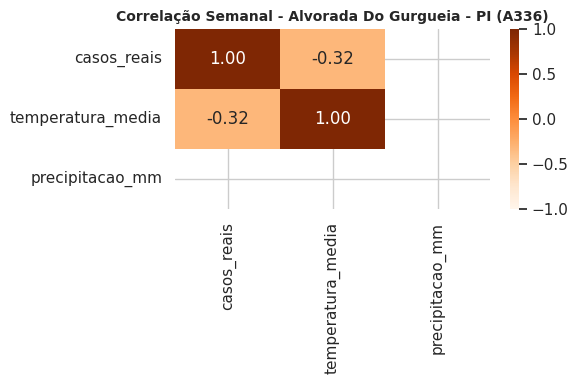

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if 'df_analise_real_2025' in globals():
    # 1. Mapeamento das Semanas Epidemiológicas (ISO Week)
    df_analise_real_2025['ano_epi'] = df_analise_real_2025['data'].dt.year
    df_analise_real_2025['semana_epi'] = df_analise_real_2025['data'].dt.isocalendar().week

    # 2. Agrupamento Semanal
    df_semanal_real_2025 = df_analise_real_2025.groupby(['ano_epi', 'semana_epi']).agg({
        'casos_reais': 'sum',
        'temperatura_media': 'mean',
        'precipitacao_mm': 'sum'
    }).reset_index()

    # Determinar nome da cidade selecionada para o título dinâmico
    nome_estacao_ativa = select_estacao.value if ('select_estacao' in globals() and select_estacao.value) else "Estação Selecionada"

    print(f"Dados agregados por Semana Epidemiológica para: {nome_estacao_ativa}")
    display(df_semanal_real_2025.head(10))

    # 3. Correlação de Pearson Semanal
    correlacao_real = df_semanal_real_2025[['casos_reais', 'temperatura_media', 'precipitacao_mm']].corr()
    plt.figure(figsize=(6, 4))
    sns.heatmap(correlacao_real, annot=True, cmap='Oranges', fmt='.2f', vmin=-1, vmax=1)
    plt.title(f'Correlação Semanal - {nome_estacao_ativa}', fontsize=10, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print("ERRO: Dataset de análise integrada 'df_analise_real_2025' não está disponível. Por favor, execute a célula anterior.")

### 4.2 Monitoramento Temporal de Variáveis Bioclimáticas

Visualização gráfica comparando as tendências de elevação da temperatura com o comportamento de novas notificações epidemiológicas.

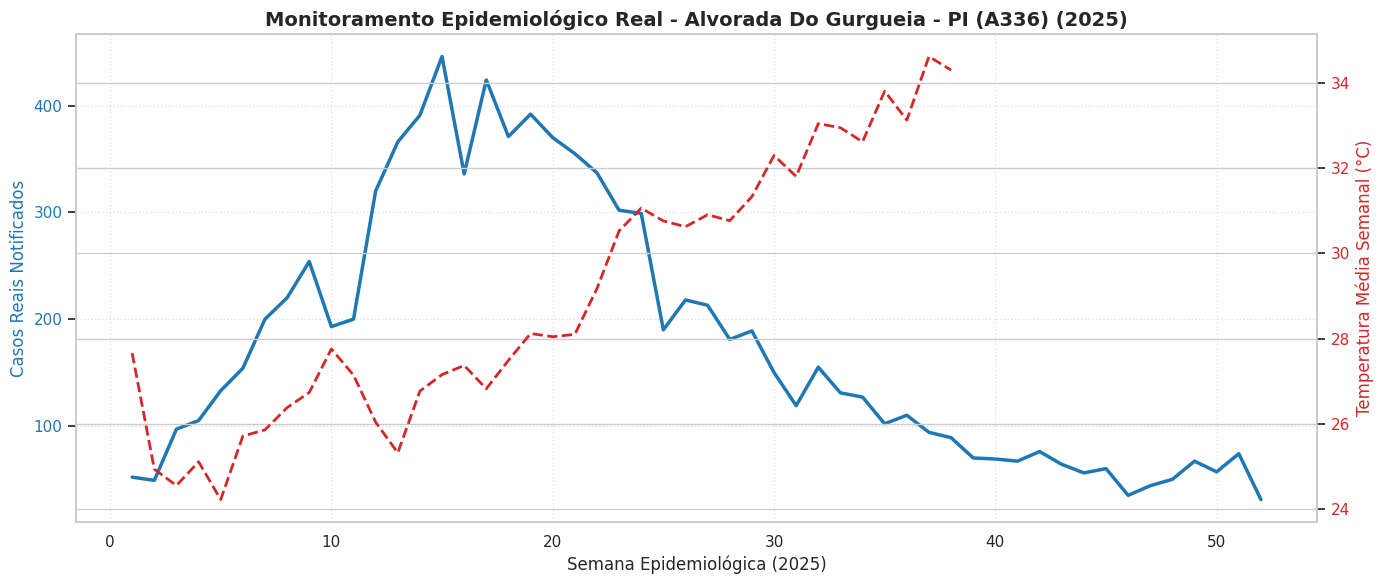

In [21]:
if 'df_semanal_real_2025' in globals():
    fig, ax1 = plt.subplots(figsize=(14, 6))

    # Nome dinâmico para o gráfico
    nome_estacao_grafico = select_estacao.value if ('select_estacao' in globals() and select_estacao.value) else "Estação Selecionada"

    color = 'tab:blue'
    ax1.set_xlabel('Semana Epidemiológica (2025)', fontsize=12)
    ax1.set_ylabel('Casos Reais Notificados', color=color, fontsize=12)
    ax1.plot(df_semanal_real_2025['semana_epi'], df_semanal_real_2025['casos_reais'], color=color, linewidth=2.5, label='Casos Reais')
    ax1.tick_params(axis='y', labelcolor=color)
    ax1.grid(True, linestyle=':', alpha=0.6)

    ax2 = ax1.twinx()
    color = 'tab:red'
    ax2.set_ylabel('Temperatura Média Semanal (°C)', color=color, fontsize=12)
    ax2.plot(df_semanal_real_2025['semana_epi'], df_semanal_real_2025['temperatura_media'], color=color, linestyle='--', linewidth=2, label='Temp. Média')
    ax2.tick_params(axis='y', labelcolor=color)

    plt.title(f'Monitoramento Epidemiológico Real - {nome_estacao_grafico} (2025)', fontsize=14, fontweight='bold')
    fig.tight_layout()
    plt.show()
else:
    print("ERRO: Dados semanais de análise não disponíveis. Certifique-se de executar as células anteriores.")